## Comparación de modelos de clasificación: SVM y SGDClassifier

### Objetivo

El objetivo de este trabajo es comparar el desempeño de dos algoritmos de clasificación supervisada: Support Vector Machine (SVM) y Stochastic Gradient Descent Classifier (SGDClassifier).

Para ello se utilizará el dataset Adult Census Income, que contiene información demográfica y laboral de individuos. El propósito será predecir si una persona posee ingresos superiores o inferiores a 50.000 dólares anuales.

# Comprensión del problema

Nos encontramos ante un problema de clasificación supervisada.

El objetivo es predecir si una persona percibe ingresos anuales mayores o menores a 50.000 dólares a partir de características personales y laborales.

La variable objetivo es "income", mientras que las demás variables funcionarán como variables predictoras.

Se trata de una clasificación binaria porque existen únicamente dos posibles categorías:

- Menor o igual que 50K
- Mayor que 50K

Este tipo de problema es habitual en Machine Learning cuando se desea predecir una categoría a partir de información histórica.

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.svm import SVC

from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("adult.csv")

df.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


**Exploracion del dataset**

In [3]:
df.shape

(48842, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              48842 non-null  int64 
 1   workclass        48842 non-null  object
 2   fnlwgt           48842 non-null  int64 
 3   education        48842 non-null  object
 4   educational-num  48842 non-null  int64 
 5   marital-status   48842 non-null  object
 6   occupation       48842 non-null  object
 7   relationship     48842 non-null  object
 8   race             48842 non-null  object
 9   gender           48842 non-null  object
 10  capital-gain     48842 non-null  int64 
 11  capital-loss     48842 non-null  int64 
 12  hours-per-week   48842 non-null  int64 
 13  native-country   48842 non-null  object
 14  income           48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [5]:
df.isnull().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [6]:
df.describe()


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [7]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

## Exploración inicial

El dataset contiene información demográfica, educativa y laboral de distintos individuos.

Posee variables numéricas y categóricas, lo que requiere una etapa de preprocesamiento antes del entrenamiento de los modelos.

La variable objetivo es income, que indica si una persona posee ingresos anuales superiores o inferiores a 50.000 dólares.

In [8]:
df["income"].value_counts()

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

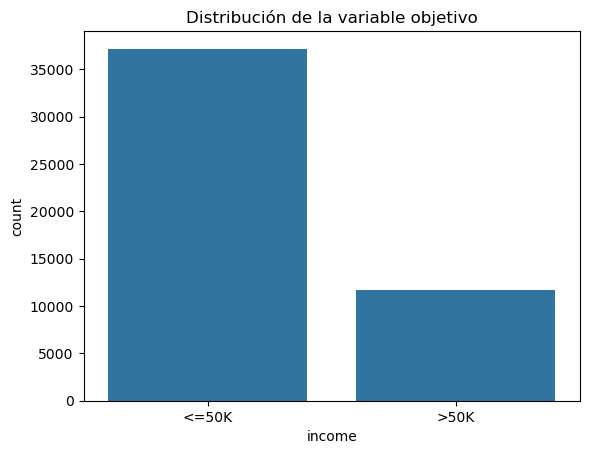

In [9]:
sns.countplot(data=df, x="income")
plt.title("Distribución de la variable objetivo")
plt.show()


## Distribución de la variable objetivo

Antes de entrenar los modelos es importante analizar la distribución de las clases.

La variable objetivo es income y representa si una persona posee ingresos mayores o menores a 50.000 dólares por año.

Observar la proporción de cada categoría permite detectar posibles desbalances que podrían afectar el rendimiento de los modelos.

In [10]:
df = df.replace("?", np.nan)

In [11]:
df.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

## Tratamiento de valores faltantes

En este conjunto de datos los valores faltantes se encuentran representados mediante el símbolo "?".

Para facilitar el preprocesamiento se reemplazaron estos valores por NaN, permitiendo que Scikit-Learn los trate correctamente mediante técnicas de imputación.

In [12]:
X = df.drop("income", axis=1)
y = df["income"]

In [13]:
numeric_features = X.select_dtypes(include=["int64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

In [14]:
print("Numéricas:")
print(numeric_features)

print("\nCategóricas:")
print(categorical_features)

Numéricas:
Index(['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

Categóricas:
Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'gender', 'native-country'],
      dtype='object')


# Preprocesamiento de datos

Los algoritmos de Machine Learning requieren datos numéricos para poder realizar cálculos y detectar patrones.

Por este motivo fue necesario preparar el dataset mediante:

- Imputación de valores faltantes.
- Transformación de variables categóricas.
- Estandarización de variables numéricas.

Estas transformaciones permiten mejorar el desempeño y la estabilidad de los modelos.

In [15]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [16]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)


## One Hot Encoding

Las variables categóricas contienen texto que los algoritmos no pueden interpretar directamente.

One Hot Encoding transforma cada categoría en una columna binaria con valores 0 y 1.

De esta forma el modelo puede trabajar correctamente con información como el nivel educativo, ocupación, país de origen o estado civil.


In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

## División del conjunto de datos

El conjunto de datos fue dividido en:

- 80% para entrenamiento.
- 20% para prueba.

El conjunto de entrenamiento permite que el modelo aprenda los patrones existentes.

El conjunto de prueba se utiliza para evaluar el rendimiento sobre datos que no fueron observados durante el entrenamiento.

In [19]:
df["income"].value_counts()

income
<=50K    37155
>50K     11687
Name: count, dtype: int64

# Modelo 1: Support Vector Machine (SVM)

Support Vector Machine es un algoritmo de clasificación supervisada.

Su objetivo es encontrar un hiperplano capaz de separar las distintas clases presentes en los datos.

Para lograrlo busca maximizar la distancia entre dicho hiperplano y los registros más cercanos de cada clase, conocidos como vectores de soporte.

Esta estrategia permite obtener modelos con buena capacidad de generalización.

In [ ]:
svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC())
    ]
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

In [20]:
df.isnull().sum()

age                   0
workclass          2799
fnlwgt                0
education             0
educational-num       0
marital-status        0
occupation         2809
relationship          0
race                  0
gender                0
capital-gain          0
capital-loss          0
hours-per-week        0
native-country      857
income                0
dtype: int64

## Análisis de la variable objetivo

La variable objetivo del problema es income, que indica si una persona percibe ingresos anuales superiores o inferiores a 50.000 dólares.

Se observa que la clase <=50K posee una mayor cantidad de registros que la clase >50K. Aunque existe cierto desbalance, ambas categorías cuentan con suficientes observaciones para entrenar y evaluar los modelos de clasificación.

También se detectaron valores faltantes en algunas variables categóricas como workclass, occupation y native-country. Estos valores serán tratados mediante técnicas de imputación durante el proceso de preprocesamiento.

## Entrenamiento del modelo SVM

In [23]:
svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC())
    ]
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

**Metricas**

In [24]:
print("Accuracy SVM:", accuracy_score(y_test, y_pred_svm))

Accuracy SVM: 0.8605793837649708


In [25]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      7479
        >50K       0.76      0.59      0.67      2290

    accuracy                           0.86      9769
   macro avg       0.82      0.77      0.79      9769
weighted avg       0.85      0.86      0.85      9769



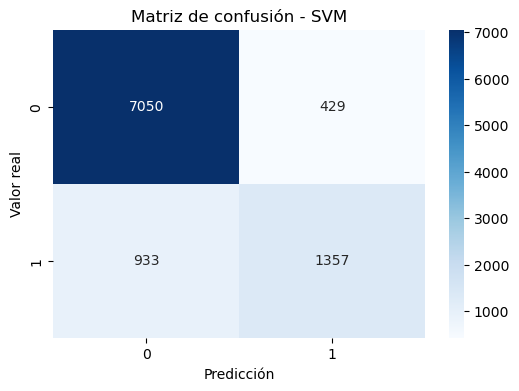

In [26]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(6,4))
sns.heatmap(cm_svm,
            annot=True,
            fmt="d",
            cmap="Blues")
plt.title("Matriz de confusión - SVM")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

## Evaluación del modelo SVM

El modelo obtuvo una precisión general cercana al 86%.

Los resultados muestran un desempeño muy bueno para la clase de ingresos menores o iguales a 50.000 dólares.

Si bien presentó algunas dificultades para identificar correctamente los casos correspondientes a ingresos superiores a 50.000 dólares, el rendimiento global fue satisfactorio.

# Modelo 2: SGDClassifier

SGDClassifier utiliza el método de Descenso de Gradiente Estocástico para optimizar los parámetros del modelo.

Su principal ventaja es la rapidez de entrenamiento, especialmente en datasets de gran tamaño.

El algoritmo ajusta sus parámetros de forma iterativa buscando minimizar el error de clasificación.

In [28]:
sgd_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            SGDClassifier(
                random_state=42
            )
        )
    ]
)

sgd_model.fit(X_train, y_train)

y_pred_sgd = sgd_model.predict(X_test)

**Metricas**

In [29]:
print("Accuracy SGD:", accuracy_score(y_test, y_pred_sgd))

Accuracy SGD: 0.8535162247927116


In [30]:
print(classification_report(y_test, y_pred_sgd))

              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.91      7479
        >50K       0.70      0.65      0.67      2290

    accuracy                           0.85      9769
   macro avg       0.80      0.78      0.79      9769
weighted avg       0.85      0.85      0.85      9769



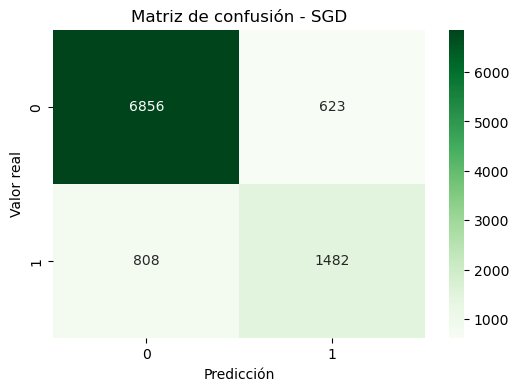

In [31]:
cm_sgd = confusion_matrix(y_test, y_pred_sgd)

plt.figure(figsize=(6,4))
sns.heatmap(cm_sgd,
            annot=True,
            fmt="d",
            cmap="Greens")
plt.title("Matriz de confusión - SGD")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.show()

## Evaluación del modelo SGDClassifier

El modelo obtuvo una precisión general cercana al 85%.

Su rendimiento fue similar al alcanzado por SVM, aunque ligeramente inferior.

A pesar de esta diferencia, demostró ser una alternativa eficiente gracias a su simplicidad y velocidad de entrenamiento.

In [32]:
acc_svm = accuracy_score(y_test, y_pred_svm)
acc_sgd = accuracy_score(y_test, y_pred_sgd)

comparacion = pd.DataFrame({
    "Modelo": ["SVM", "SGD"],
    "Accuracy": [acc_svm, acc_sgd]
})

comparacion

,Modelo,Accuracy
0,SVM,0.860579
1,SGD,0.853516


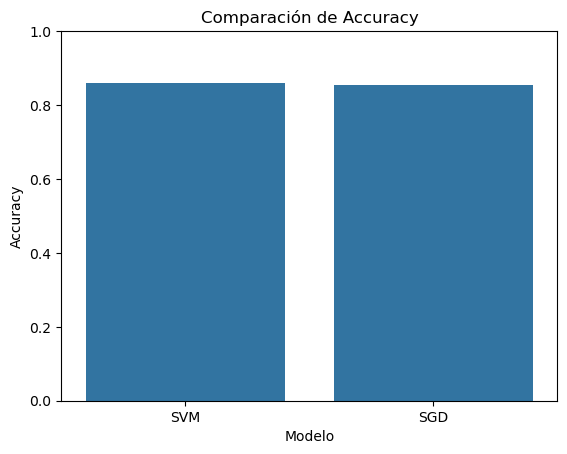

In [33]:
sns.barplot(
    data=comparacion,
    x="Modelo",
    y="Accuracy"
)

plt.title("Comparación de Accuracy")
plt.ylim(0,1)
plt.show()

In [34]:
print("Accuracy SVM:", accuracy_score(y_test, y_pred_svm))

Accuracy SVM: 0.8605793837649708


In [35]:
print("Accuracy SGD:", accuracy_score(y_test, y_pred_sgd))

Accuracy SGD: 0.8535162247927116


In [36]:
classification_report(y_test, y_pred_svm)

'              precision    recall  f1-score   support\n\n       <=50K       0.88      0.94      0.91      7479\n        >50K       0.76      0.59      0.67      2290\n\n    accuracy                           0.86      9769\n   macro avg       0.82      0.77      0.79      9769\nweighted avg       0.85      0.86      0.85      9769\n'

In [37]:
classification_report(y_test, y_pred_sgd)

'              precision    recall  f1-score   support\n\n       <=50K       0.89      0.92      0.91      7479\n        >50K       0.70      0.65      0.67      2290\n\n    accuracy                           0.85      9769\n   macro avg       0.80      0.78      0.79      9769\nweighted avg       0.85      0.85      0.85      9769\n'

# Métricas utilizadas

Accuracy:
Representa el porcentaje total de predicciones correctas realizadas por el modelo.

Precision:
Indica qué proporción de las predicciones positivas fueron correctas.

Recall:
Mide la capacidad del modelo para detectar correctamente los casos positivos.

F1-Score:
Combina Precision y Recall en una única métrica, proporcionando una evaluación equilibrada del rendimiento.

## Evaluación del modelo SVM

El modelo Support Vector Machine obtuvo una precisión general (accuracy) del 86,06%.

Los resultados muestran un excelente desempeño para la clase de ingresos menores o iguales a 50.000 dólares, alcanzando un F1-Score de 0,91.

Respecto de la clase de ingresos superiores a 50.000 dólares, el modelo presentó mayores dificultades, obteniendo un F1-Score de 0,67. Esto puede deberse al desbalance existente entre ambas clases en el conjunto de datos.

En términos generales, SVM logró un desempeño sólido y una buena capacidad de generalización sobre los datos de prueba.

## Evaluación del modelo SGDClassifier

El modelo SGDClassifier obtuvo una precisión general del 85,35%.

Los resultados obtenidos fueron similares a los alcanzados por SVM, especialmente para la clase de ingresos menores o iguales a 50.000 dólares.

Si bien el modelo logró identificar una porción importante de los casos de ingresos superiores a 50.000 dólares, su rendimiento global fue ligeramente inferior al de SVM.

Una de las principales ventajas de SGDClassifier es su eficiencia computacional y su rapidez de entrenamiento cuando se trabaja con grandes volúmenes de datos.

# Conclusión

En este trabajo se compararon dos algoritmos de clasificación supervisada: Support Vector Machine (SVM) y SGDClassifier, utilizando el dataset Adult Census Income para predecir si una persona posee ingresos superiores o inferiores a 50.000 dólares anuales.

Luego de realizar el preprocesamiento de los datos, el entrenamiento de los modelos y la evaluación mediante métricas de clasificación, ambos algoritmos demostraron un buen desempeño.

El modelo SVM obtuvo una precisión general del 86,06%, mientras que SGDClassifier alcanzó un 85,35%. Aunque la diferencia fue pequeña, SVM presentó los mejores resultados globales y una mayor capacidad para clasificar correctamente los registros del conjunto de prueba.

Por este motivo, considero que Support Vector Machine fue el modelo más adecuado para este problema de clasificación, ya que logró el mejor equilibrio entre precisión y capacidad predictiva. Sin embargo, SGDClassifier también resultó una alternativa válida debido a su simplicidad y eficiencia computacional.